## iraqdata — إنهاء معاناة جمع البيانات الاقتصادية في العراق
### الدرس 02: البحث في البيانات الاقتصادية باللغة العربية
التحليل الكمي للاقتصاد العراقي باستخدام بايثون

**المكتبة المستخدمة:** 

iraqdata (v1.0.0):

[https://github.com/HusseinKh90/iraqdata](https://github.com/HusseinKh90/iraqdata)

[https://pypi.org/project/iraqdata/](https://pypi.org/project/iraqdata/)

---
### الهدف من هذا الملف:
التعرف على محرك البحث المدمج في المكتبة للبحث في أكثر من 60 مؤشراً اقتصادياً للعراق باللغة العربية مباشرة، دون القلق من حساسية الهمزات أو التشكيل أو مسميات الجداول الرسمية المعقدة.

In [1]:
# لتثبيت مكتبة البيانات لأول مرة
!pip install iraqdata

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# استيراد المكتبات وضمان تثبيت الإصدار المعتمد
import iraqdata as id
import pandas as pd
import matplotlib.pyplot as plt

id.set_release("data-2026-10")
print(f"تم استيراد iraqdata بنجاح — الإصدار: {id.__version__}")

تم استيراد iraqdata بنجاح — الإصدار: 1.0.0


In [3]:
# 1. البحث عن مؤشرات التضخم باللغة العربية
# المحرك يطوي الهمزات والتشكيل تلقائياً (تضخم / تضخّم / التضخم)
results_inflation = id.search("تضخم")
results_inflation[["series_id", "name_ar", "frequency", "unit", "start_date"]].head()

,series_id,name_ar,frequency,unit,start_date
0,cpi.core_1993,التضخم الأساس (أساس 1993 = 100),monthly,INDEX,2004-01
1,cpi.core_2007,التضخم الأساس (أساس 2007 = 100),monthly,INDEX,2009-01
2,cpi.core_2012,التضخم الأساس (أساس 2012 = 100),monthly,INDEX,2015-01
3,cpi.core_2022,التضخم الأساس (أساس 2022 = 100),monthly,INDEX,2023-01
4,cpi_core,الرقم القياسي للتضخم الأساس (سلسلة مترابطة، 20...,monthly,INDEX,2004-01


In [4]:
# 2. البحث عن مؤشرات النفط الخام والإنتاج والتصدير
results_oil = id.search("نفط")
results_oil[["series_id", "name_ar", "frequency", "unit", "source"]].head(6)

,series_id,name_ar,frequency,unit,source
0,oil_price_basrah,معدل سعر نفط البصرة (خام البصرة الخفيف / المتوسط),monthly,USD_PER_BBL,OPEC MOMR
1,crude_production_secondary,إنتاج النفط الخام (المصادر الثانوية),monthly,TB_PER_D,U.S. EIA
2,crude_production_direct,إنتاج النفط الخام (الاتصال المباشر - وزارة النفط),monthly,TB_PER_D,JODI-Oil / OPEC MOMR
3,trade.exports_crude_oil,صادرات النفط الخام (فوب),quarterly,MILLION_USD,Central Bank of Iraq (CBI)
4,trade.exports_oil_products,صادرات المشتقات النفطية (فوب),quarterly,MILLION_USD,Central Bank of Iraq (CBI)
5,trade.exports_nonoil,الصادرات السلعية غير النفطية (فوب),quarterly,MILLION_USD,Central Bank of Iraq (CBI)


In [5]:
# 3. البحث عن الاحتياطيات الأجنبية والبنك المركزي
results_reserves = id.search("احتياطي")
results_reserves[["series_id", "name_ar", "frequency", "unit", "start_date"]]

,series_id,name_ar,frequency,unit,start_date
0,money.reserves_official,الاحتياطيات الأجنبية الرسمية للبنك المركزي,monthly,BILLION_IQD,2004-01
1,money.required_reserves,الاحتياطي القانوني الإلزامي,monthly,BILLION_IQD,2004-12
2,bop.reserve_assets_change,الأصول الاحتياطية (صافي التغير),quarterly,MILLION_USD,2013-Q1


C:\Users\msi-pc\AppData\Local\Temp\ipykernel_2900\3718802531.py:3: FlagWarning: Result contains break (B) or provisional (P) values: money.reserves_official 1 B, 1 P. Pass flags=True to see them.
  reserves = id.get_series("money.reserves_official", start="2015-01")


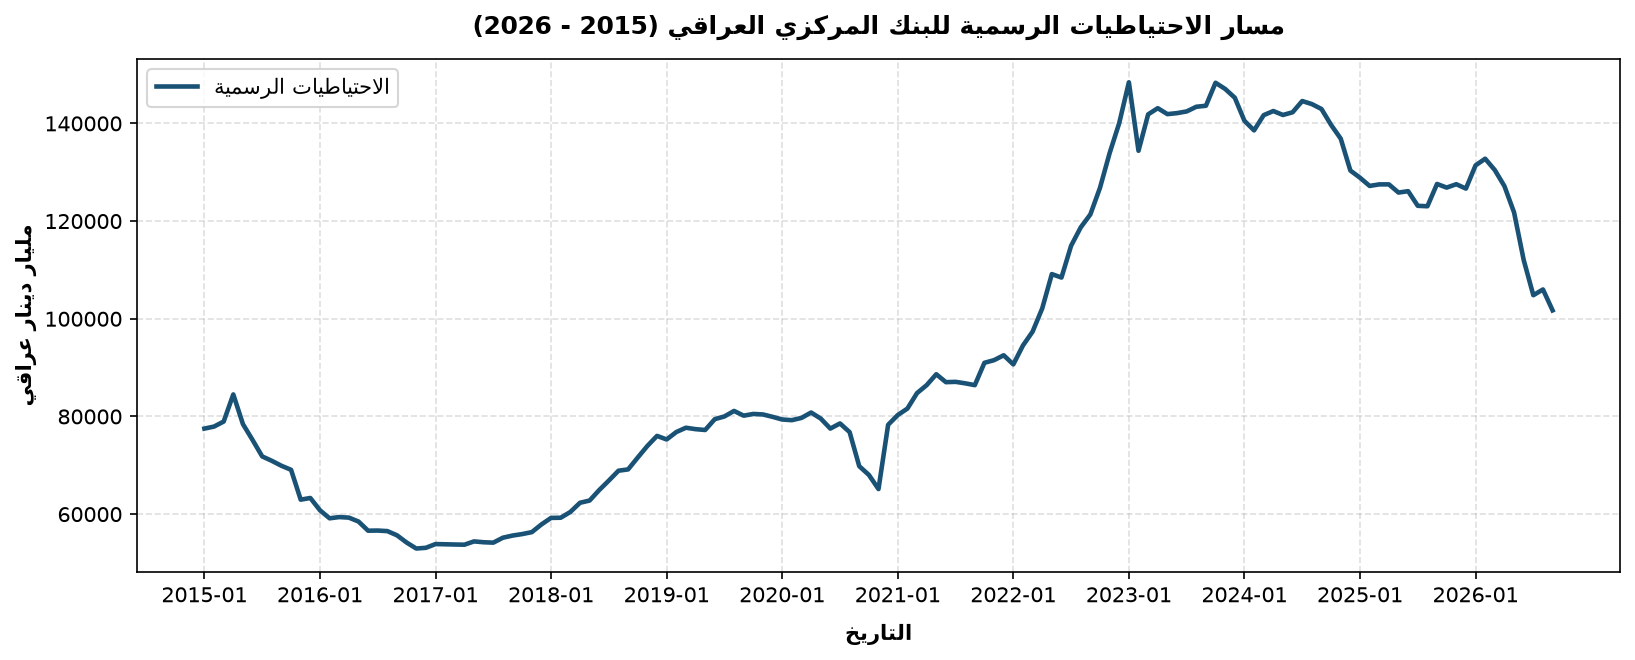

In [6]:
# 4. من البحث إلى الرسم البياني مباشرة في خطوتين:
# وجدنا من البحث أن رمز الاحتياطيات هو 'money.reserves_official'
reserves = id.get_series("money.reserves_official", start="2015-01")

# رسم مسار الاحتياطيات الرسمية للبنك المركزي العراقي
fig, ax = plt.subplots(figsize=(11, 4.5), dpi=150)

# رسم الخط البياني
ax.plot(reserves.index, reserves["money.reserves_official"], color="#1a5276", lw=2.2, label="الاحتياطيات الرسمية")
ax.set_title("مسار الاحتياطيات الرسمية للبنك المركزي العراقي (2015 - 2026)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("مليار دينار عراقي", fontsize=10, fontweight="bold")
ax.set_xlabel("التاريخ", fontsize=10, fontweight="bold", labelpad=8)

# ضبط تباعد التواريخ أفقياً لمنع التداخل
step = 12  # عرض سنة كاملة لكل علامة
ax.set_xticks(range(0, len(reserves.index), step))
ax.set_xticklabels(reserves.index[::step], rotation=0, fontsize=10)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper left", frameon=True, facecolor="white")

fig.tight_layout()
plt.show()

### الخلاصة والنتيجة:
1. محرك البحث `id.search()` يتيح لك استكشاف أي مؤشر باللغة العربية دون الحاجة لحفظ رموز السلاسل مسبقاً.
2. بمجرد إيجاد الرمز من البحث، يمكنك استدعاء السلسلة وتحليلها أو رسمها مباشرة بخطوة واحدة.

iraqdata (v1.0.0):

https://github.com/HusseinKh90/iraqdata

https://pypi.org/project/iraqdata/